# Does coarse-graining change the ordering evidence?

**Question:** How do entropy, symbolic complexity and time reversal describe different aspects of the same observed sequence? We use the structural-break case rather than replacing it with an idealized process, and keep a constant sequence as a control with a known answer. The aim is to understand each calculation's information and units. None of these summaries, by itself, identifies a forecasting winner or demonstrates a deterministic physical mechanism.

## Objectives

Calculate coarse-grained entropy with fixed original tolerance, inspect binary phrase counts, compare time reversal and repeat a locally seeded robust fit. Identify missing estimates before interpreting a curve.

## Setup

The environment includes the sequence implementation, its numerical libraries and the seeded robust estimator. All inputs for the worked case are committed. An observation index means the same original interval throughout the lesson. This matters when a coarse-grained block represents several observations: its scale is an operation on the original data, not a label attached to a resampled plotting coordinate.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1


In [1]:
# Configure a portable session and suppress only the known repeated-shape control warning.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.analysis.sequence import matrix_profile, sequence_report
from chronoscopelab.analysis.sequence import multiscale_entropy, time_reversal
from chronoscopelab.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Data

The admitted artifact preserves the source identity and the observations used below.


In [2]:
# Read every original observation from the admitted structural-break case.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print("Original observations:", len(values))


Original observations: 300


## Method

Costa multiscale entropy forms one reduced sequence per scale by averaging non-overlapping blocks. A scale of four retains the mean of each successive four-observation block and discards only an incomplete terminal block. Sample entropy then compares short patterns in that reduced sequence. The order is two: we ask whether similar two-observation patterns remain similar when extended to a third observation, excluding self matches from both counts.


In [3]:
# Keep the original tolerance fixed while coarse-graining at four scales.
entropy = multiscale_entropy(values, scales=(1, 2, 4, 8))
print("Original tolerance:", round(entropy["scales"][0]["tolerance"], 4))
for row in entropy["scales"]:
    print("Scale", row["scale"], "n", row["n"], "SampEn", row["entropy"])


Original tolerance: 1.6917
Scale 1 n 300 SampEn 1.2522944746943416
Scale 2 n 150 SampEn 0.9624020838335607
Scale 4 n 75 SampEn 0.3980301296206462
Scale 8 n 37 SampEn 0.6931471805599453


Tolerance is fixed to a fraction of the original standard deviation. It does not shrink or expand independently with each reduced sequence. Re-estimating tolerance at every scale could make some curves appear artificially similar and would answer a different question. The output includes matching pair counts and observation counts, making a missing estimate inspectable. An absent value can arise because there are too few reduced observations or because no template extensions match; neither situation means zero complexity.


In [4]:
# Separate a legitimate zero entropy from insufficient coarse observations.
constant = multiscale_entropy(np.ones(100), scales=(1, 2, 4, 8))
print("Constant-series scale-one entropy:", constant["scales"][0]["entropy"])
print("Short coarse estimate:", constant["scales"][-1]["entropy"])


Constant-series scale-one entropy: -0.0
Short coarse estimate: None


The constant control separates unavailable estimation from a legitimate zero. When enough observations remain, every eligible pair and extension matches, so the entropy is zero. At a coarse scale with fewer than twenty observations, the product intentionally reports no estimate. The sample-size boundary is a declared reporting rule, not a theorem that all longer estimates are reliable. Short finite sequences can still produce unstable counts near the tolerance threshold.

Time-reversal asymmetry examines a third-order lagged moment. We use lag two and compute the same statistic after reversing the observations. The raw result has cubed source units; standardization before calculation removes location and scale. Reversing the complete ordering exchanges the two terms and changes the sign, which provides an exact structural check. It does not supply a p value or establish that a finite departure is statistically significant.


In [5]:
# Compute the same lag statistic on forward and reversed observations.
forward = time_reversal(values, lag=2)
backward = time_reversal(values[::-1], lag=2)
print("Forward standardized statistic:", round(forward["standardized"], 6))
print("Reversed standardized statistic:", round(backward["standardized"], 6))


Forward standardized statistic: 0.000749
Reversed standardized statistic: -0.000749


Lempel-Ziv complexity takes another route. Values above the median become one, and all other values become zero. The resulting binary sequence is parsed into new phrases. We retain the phrase count as well as its asymptotic normalization, c(n) log2(n)/n. A normalized value above one is possible for a finite sequence and is not clipped. This symbolic encoding discards amplitude information and assigns tied observations consistently; changing the threshold or alphabet changes the method.


In [6]:
# Inspect median-thresholded binary phrase counts and their normalization.
symbolic = sequence_report(values, seasonality=12)
print("Binary phrase count:", symbolic["lempel_ziv"]["raw"])
print("Normalized phrase count:", round(symbolic["lempel_ziv"]["normalized"], 4))


Binary phrase count: 13
Normalized phrase count: 0.3566


A change of positive units and an additive offset should preserve the median ordering and the standardized statistics, apart from numerical precision. It also multiplies the original entropy tolerance by the same scale factor as the observations. We run the implementation again after that transformation instead of assuming that all quantities are dimensionless. The raw third-order statistic must not be compared numerically across units without acknowledging its cubic scaling.


In [7]:
# Repeat the calculations after a positive affine unit conversion.
converted = sequence_report(values*10+100, seasonality=12)
print("Phrase count after unit conversion:", converted["lempel_ziv"]["raw"])
print("Scale-one converted entropy:", converted["multiscale_entropy"]["scales"][0]["entropy"])


Phrase count after unit conversion: 13
Scale-one converted entropy: 1.2522944746943416


## Results

**Answer:** The binary phrase count is 13 and its normalization is 0.3566. The entropy curve varies with scale under one fixed original tolerance, while the binary phrase count describes a different representation. Reversal changes the signed lag statistic. None of these descriptive values alone certifies chaos, significance or forecast accuracy.


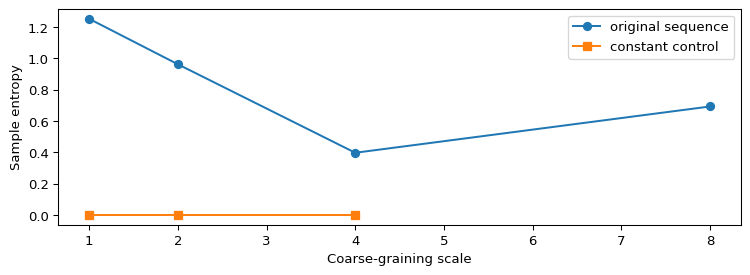

In [8]:
# Compare the observed case with the constant control under the same scale policy.
fig, ax = plt.subplots()
ax.plot([r["scale"] for r in entropy["scales"]],
        [r["entropy"] for r in entropy["scales"]], marker="o", label="original sequence")
ax.plot([r["scale"] for r in constant["scales"]],
        [r["entropy"] for r in constant["scales"]], marker="s", label="constant control")
ax.set(xlabel="Coarse-graining scale", ylabel="Sample entropy")
ax.legend()
fig.tight_layout()
plt.show()


The two curves share a declared tolerance convention, but they describe different sequences. The case curve can change as local ordering is averaged away, whereas the constant control remains at zero wherever the sample-size rule admits an estimate. Missing endpoints should remain visible as missing values. A falling curve alone does not prove randomness, and a sustained curve does not prove useful long-range forecast information in this finite, nonstationary record.


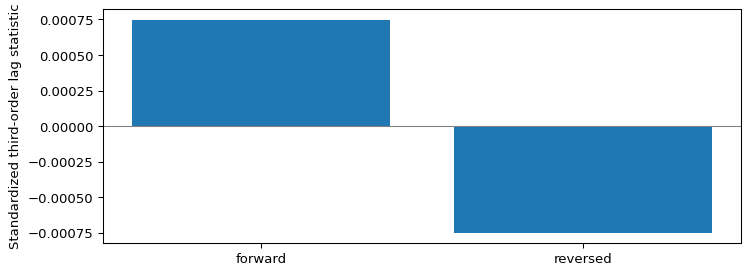

In [9]:
# Display the signed standardized lag statistic in both directions.
fig, ax = plt.subplots()
ax.bar(["forward", "reversed"], [forward["standardized"], backward["standardized"]])
ax.axhline(0, color="grey", linewidth=.8)
ax.set(ylabel="Standardized third-order lag statistic")
fig.tight_layout()
plt.show()


The bars visualize a sign reversal under a known ordering transformation. Their magnitudes refer to standardized observations, so their labels do not inherit the raw source's cubic units. The symmetric appearance is a property of the statistic under reversal, not independent evidence for a physical direction of time. A surrogate experiment or another properly specified test would be needed to interpret statistical departures under a particular null model.

Answer: the case tolerance is 1.6917 and stays fixed across the entropy scales. The constant control has scale-one entropy zero, while its short coarse endpoint is unavailable. These outputs distinguish a measured zero from an estimation boundary. The symbolic phrase count survives the positive unit conversion; the reversed standardized statistic changes sign. Together they illustrate why several diagnostics can be useful without treating them as interchangeable estimates of a single hidden quantity called complexity.

The seeded nonlinear slope calculation addresses a different reproducibility issue. Its robust fit uses a local random_state over the library's exposed log-distance data. Repeating that fit should not depend on random draws made by another caller. The pipeline derives a seed from case identity and its supplied seed, and retains the surrogate gate before any chaos verdict. Deterministic numerical output is a necessary implementation property, not evidence that the observed process itself is deterministic.


In [10]:
# Repeat robust nonlinear estimates with an explicit local seed.
from chronoscopelab.analysis.nonlinear import chaos_measures
first_fit = chaos_measures(values, seed=42)
second_fit = chaos_measures(values, seed=42)
print("Repeated robust estimates identical:", first_fit == second_fit)
print("Correlation dimension:", round(first_fit.corr_dim, 6))


Repeated robust estimates identical: True
Correlation dimension: 1.570235


### Limitations

The structural-break case contains changing levels and a finite observation budget. Global entropy and asymmetry summaries can combine several regimes rather than identify one stable mechanism. Binary symbolization hides amplitude distinctions and can be sensitive to ties. Matching counts depend on order, tolerance and length. The M4 study therefore treats these values as prefix features with a declared protocol, tests their association with subsequent error, and keeps negative findings rather than interpreting every irregular curve as predictive structure.

## Summary

Entropy, phrase counts and lagged moments discard different information. Their units, unavailable values and reproducibility conditions are part of the result rather than optional annotations.

### Reproduce

Execute each method call and both figures in order. Confirm the reported tolerance, the constant control's zero and missing endpoint, the phrase-count comparison and the repeated robust estimates. The repository's independent pair-count and RNG-state tests cover numerical properties beyond these worked outputs; this lesson provides an interpretable example rather than replacing those tests with a graph.

## References

Costa, Goldberger and Peng, DOI 10.1103/PhysRevLett.89.068102. Lempel and Ziv, DOI 10.1109/TIT.1976.1055501. The tsfresh feature definition specifies the lagged third-order reversal statistic, and nolds documents the correlation-dimension and Lyapunov fitting data used by the seeded adapter.

[Nolds fitting documentation](https://cschoel.github.io/nolds/nolds.html).
